# V3: 250 замен простых текстов

Два обучения с одинаковыми параметрами и порядком: public3398 + v3train3000 + прежние авторские100 =6498 строк. Заменены250 строк v3 на50сюжетов по5версий. Распределения source и меток102–106 сохранены. TF-IDF word(1,3)+char_wb(3,5),18k+28k,SGD,seed42,пороги0.5. Notebook только читает измерения.

250новых строк не являются250независимыми сюжетами. Public729 — validation. Official208 содержит конфликты и пересечения; clean114 — диагностический срез. Проверки уже использовались, public test повлиял на направления дополнения. Независимый финальный тест отсутствует. Авторские метки не проходили независимую человеческую перепроверку.

In [1]:
from pathlib import Path
import json
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display,Markdown,Image
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'avito_compare').exists() and (p/'output').exists())
P=ROOT/'output/v3-revision3-study'
s=json.loads((P/'summary.json').read_text());runs=s['runs']
display(Markdown((P/'report.md').read_text()))
assert s['protocol']['train_rows']==6498
assert runs['before']['fit']['thresholds']==runs['after']['fit']['thresholds']==[.5]*5


# Замена 250 простых текстов v3: сравнение до/после

Обе модели обучены заново на 6498 строках: public3398 + v3train3000 + прежние авторские100. В v3 заменены250 строк на50 контрастных сюжетов по5версий. Число строк, порядок, source и распределение обучающих/целевых меток102–106 сохранены. Word(1,3), char_wb(3,5),18k+28k,sublinear_tf=True, прежнийSGD,seed42,пороги0.5. Словарь переобучен только на train. Исходные v3 и проверочные части не изменены.

| Выборка | F1 до | F1 после | Δ, п.п. | P после | R после | FP до→после | FN до→после |
|---|---:|---:|---:|---:|---:|---|---|
| public_validation_729 | 0.934426 | 0.931762 | -0.266 | 0.935608 | 0.927948 | 118→117 | 122→132 |
| v3_validation | 0.637046 | 0.607856 | -2.919 | 0.845878 | 0.474372 | 94→86 | 486→523 |
| v3_test | 0.681818 | 0.639798 | -4.202 | 0.856661 | 0.510553 | 107→85 | 425→487 |
| v3_challenge | 0.738462 | 0.761905 | +2.344 | 0.727273 | 0.800000 | 55→45 | 30→30 |
| new_control_20 | 0.457143 | 0.400000 | -5.714 | 0.428571 | 0.375000 | 11→8 | 8→10 |
| official_public_test_208 | 0.822320 | 0.820588 | -0.173 | 0.724675 | 0.945763 | 106→106 | 15→16 |
| official_clean_unique_114 | 0.763948 | 0.758621 | -0.533 | 0.671756 | 0.871287 | 43→43 | 12→13 |

## Ресурсы и разрыв train/holdout

| Модель | Fit, с | Пик RAM, MiB | Размер, MiB | Word/char | Synthetic train F1 |
|---|---:|---:|---:|---|---:|
| before | 11.110 | 647.5 | 2.768 | 18000/28000 | 0.927934 |
| after | 10.634 | 737.2 | 2.767 | 18000/28000 | 0.924502 |

Словоформы v3train по одинаковому правилу подсчёта: 1210→2336; новых 1130, исчезнувших 4. Новых точных/близких копий в проверенных старых корпусах не найдено. Это не доказательство семантической независимости.

Public729 — validation. Official208 имеет известные конфликты и пересечения с train; clean114 — отдельный малый диагностический срез. Проверочные наборы многократно использовались, а public test повлиял на выбор направлений дополнения: прирост не доказывает качество на неизвестном финальном тесте. Новые250 — авторская разметка и самооценка, не независимый gold. Веса production не заменялись. Время измерено однократно.

## Вывод

**Ревизию не продвигаем как основной train.** Расширение лексики не улучшило главные проверки: V3test -4,20п.п., publicvalidation -0,27п.п., publictest -0,17п.п. На V3test FP уменьшились22, но FN выросли62. Улучшение challenge +2,34п.п. не компенсирует ухудшение остальных срезов. На control20 снижение -5,71п.п., но там всего10сценариев.

Эксперимент проверял замену: одновременно убраны250старых и добавлены250новых текстов. Он не изолирует эффект удаления полезных простых примеров от эффекта новых формулировок. Аддитивное включение и проверка на разбиении по семействам могут быть следующими сравнениями; здесь они не запускались. Новые данные сохранены отдельно как авторский контрастный материал. Нет оснований заявлять, что переобучение устранено или модель стала лучше обобщать.

## Отсечение новых признаков

В новых250текстах обнаружено6582словесныхn-граммы, отсутствовавших во всём прежнемtrain6498. Из них5354не проходятmin_df2; оставшиеся1228полностью отсеченыmax_features18000 словесной ветки. Это не означает, что модель не видит текст: символьная ветка сохраняет часть информации, известные словесные признаки тоже остаются. Подробности:feature_cap_audit.json. Все новые признаки не обязательно полезны.

Последующая проверка60k/100k и небольшого снижения порога находится в ../v3-revision3-caps/report.md. Большая размерность не восстановила F1, порог0,45 помогv3, но ухудшилpublictest. Порог выбран наcalibration1328, поэтомуv3validation600 после этого не является независимой проверкой.


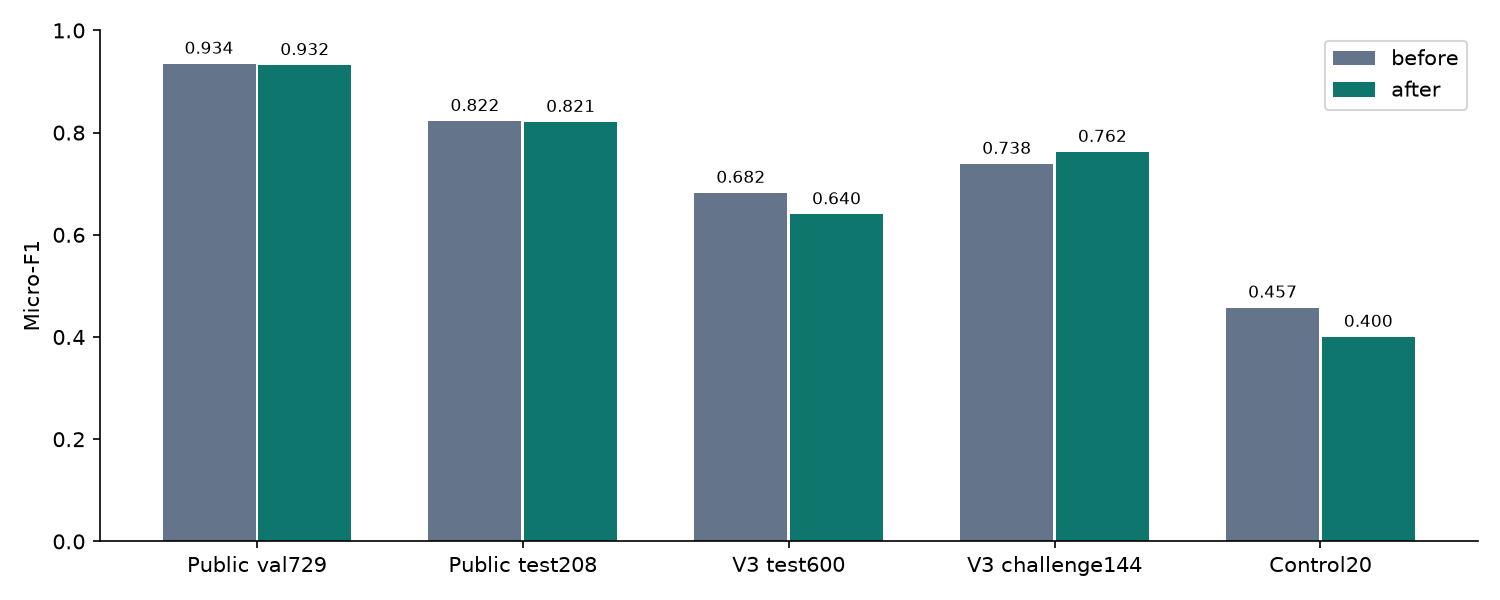

In [2]:
keys=['public_validation_729','official_public_test_208','v3_test','v3_challenge','new_control_20']
labels=['Public val729','Public test208','V3 test600','V3 challenge144','Control20']
x=list(range(len(keys)))
fig,ax=plt.subplots(figsize=(10,4))
for offset,name,color in [(-.18,'before','#64748b'),(.18,'after','#0f766e')]:
    bars=ax.bar([i+offset for i in x],[runs[name]['evaluation'][k]['micro_f1'] for k in keys],width=.35,label=name,color=color)
    ax.bar_label(bars,fmt='%.3f',fontsize=8,padding=3)
ax.set_xticks(x,labels);ax.set_ylim(0,1);ax.set_ylabel('Micro-F1');ax.legend();ax.spines[['top','right']].set_visible(False)
fig.tight_layout();fig.savefig(P/'comparison.png',dpi=150);plt.close(fig)
display(Image(filename=str(P/'comparison.png')))


## Решение

Рекомендация: **не заменять исходный v3 этой ревизией как основным train**. Лексика выросла1210→2336словоформ, но V3testF1 снизился0.6818→0.6398: FP107→85, FN425→487. Publictestпочтибезизменений0.8223→0.8206, publicvalidation0.9344→0.9318. Challengeулучшился0.7385→0.7619; этого недостаточно для продвижения. На control20снижение0.4571→0.4000, но это всего10сценариев.

Новые тексты полезны как сохранённый контрастный материал, однако расширение словаря не гарантирует переноса линейного классификатора. Причина ухудшения отдельно не изолирована: в A/B одновременно удалялись исходные и добавлялись новые формулировки. Аддитивное включение и оценка с разбиением по семействам — возможные следующие эксперименты, **не запускались**. Рабочие веса и исходные тесты не изменены.

## Дополнительная проверка 46k/60k/100k и порога
Во всех вариантах word(1,3). Порог выбран только по public calibration728 + v3validation600; последнее теперь калибровочная часть этой серии.

In [3]:
display(Markdown((ROOT/'output/v3-revision3-caps/report.md').read_text()))

# Revision3: размерность и небольшое снижение порога

Одинаковый train6498, word(1,3),char_wb(3,5),sublinear_tf=True,SGD без изменений,seed42. Меняются только max_features. 46k взята из A/B без повторного fit. Все модели сохраняют пороги0.5; альтернативный порог применяется только для диагностической оценки и выбирается по calibration1328=public728+v3validation600.

| Лимит | Проверка | F1 при0.5 | Порог по calibration | F1 с ним | P с ним | R с ним | FP0.5→cal | FN0.5→cal |
|---|---|---:|---:|---:|---:|---:|---|---|
| 46k | public_validation_729 | 0.931762 | 0.45 | 0.934559 | 0.926045 | 0.943231 | 117→138 | 132→104 |
| 46k | v3_test_600 | 0.639798 | 0.45 | 0.677108 | 0.845113 | 0.564824 | 85→103 | 487→433 |
| 46k | v3_challenge_144 | 0.761905 | 0.45 | 0.761905 | 0.727273 | 0.800000 | 45→45 | 30→30 |
| 46k | new_control_20 | 0.400000 | 0.45 | 0.514286 | 0.473684 | 0.562500 | 8→10 | 10→7 |
| 46k | official_public_test_208 | 0.820588 | 0.45 | 0.813314 | 0.709596 | 0.952542 | 106→115 | 16→14 |
| 60k | public_validation_729 | 0.932418 | 0.45 | 0.934018 | 0.925509 | 0.942686 | 111→139 | 135→105 |
| 60k | v3_test_600 | 0.640654 | 0.45 | 0.674320 | 0.845455 | 0.560804 | 85→102 | 486→437 |
| 60k | v3_challenge_144 | 0.741935 | 0.45 | 0.761905 | 0.727273 | 0.800000 | 45→45 | 35→30 |
| 60k | new_control_20 | 0.387097 | 0.45 | 0.514286 | 0.473684 | 0.562500 | 9→10 | 10→7 |
| 60k | official_public_test_208 | 0.815906 | 0.45 | 0.812139 | 0.707809 | 0.952542 | 107→116 | 18→14 |
| 100k | public_validation_729 | 0.931657 | 0.45 | 0.932002 | 0.921558 | 0.942686 | 122→147 | 128→105 |
| 100k | v3_test_600 | 0.639900 | 0.45 | 0.667877 | 0.838906 | 0.554774 | 89→106 | 485→443 |
| 100k | v3_challenge_144 | 0.754098 | 0.45 | 0.774194 | 0.750000 | 0.800000 | 40→40 | 35→30 |
| 100k | new_control_20 | 0.400000 | 0.45 | 0.514286 | 0.473684 | 0.562500 | 8→10 | 10→7 |
| 100k | official_public_test_208 | 0.820961 | 0.45 | 0.817266 | 0.710000 | 0.962712 | 110→116 | 13→11 |

| Лимит | Word/char | Fit,с | Пик RAM,MiB | Модель,MiB |
|---|---|---:|---:|---:|
| 46k | 18000/28000 | 10.634 | 737.2 | 2.767 |
| 60k | 24000/36000 | 8.542 | 606.2 | 3.632 |
| 100k | 40000/60000 | 8.884 | 614.3 | 6.090 |

Разницы относительно46k и полные Macro-F1/P/R/FP/FN сохранены в JSON. Порог не подбирался по тестам. V3validation использована как calibration, больше не считается независимой проверкой этой серии. Публичные тесты известны, имеют конфликты и пересечения, control20 мал (10сюжетов). Метки авторские; production-веса не заменялись. Время одиночное.

## Решение

Увеличение46k→60k/100k при пороге0,5 почти не меняетv3testF1 (0,6398/0,6407/0,6399), а размер модели растёт2,77→3,63→6,09MiB. Повышение размерности в этих пределах не оправдано качеством.

Снижение порога46k до0,45 уменьшает пропуски наv3 (FN487→433), но увеличивает ложные срабатывания (FP85→103). V3F1растёт0,6398→0,6771, publictestF1снижается0,8206→0,8133. На обеих основных проверках это не превосходит прежнюю смесь до250замен (0,6818/0,8223). Рекомендация: сохранить прежнийtrain и модель как основную точку сравнения; новые данные оставить экспериментальными, универсально снижать пороги не обосновано. Во всех запусках использовались словесные триграммы(1,3).
